# Analisis Kuantitatif: Strategi 2-Candle (14.00 & 14.15 WIB)
### Model: 50 Entri Searah Tren Sesi Asia | XAU/USD (M15)

---

## 1. Parameter Model
- **Waktu Acuan**: Candle M15 pukul 14.00 dan 14.15 WIB.
- **Batas Rentang**: $High_{ref} = \max(High_{14.00}, High_{14.15})$, $Low_{ref} = \min(Low_{14.00}, Low_{14.15})$.
- **Lebar Rentang**: $Range = High_{ref} - Low_{ref}$.
- **Arah Tren Sesi Asia (07.00 - 14.00 WIB)**:
  - $\Delta Asia = Close_{13.45} - Open_{07.00}$.
  - $\Delta Asia \ge 0 ightarrow$ Bullish $ightarrow$ Pasang **BUY LIMIT** di $Low_{ref}$.
  - $\Delta Asia < 0 ightarrow$ Bearish $ightarrow$ Pasang **SELL LIMIT** di $High_{ref}$.
- **Manajemen Risiko**:
  - Stop Loss (SL) = 0.5 × Range.
  - Take Profit (TP) = 1.0 × Range (Batas sebaliknya).
  - Risk to Reward = 1 : 2 (Win = +2.0 R, Loss = -1.0 R).
- **Masa Aktif Order**: 14.30 - 22.00 WIB. Posisi aktif ditutup pada 22.00 WIB jika belum menyentuh TP/SL.


In [1]:
# 1. SETUP ENVIRONMENT
import os
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['figure.dpi'] = 120

print("Status environment: Siap.")


Status environment: Siap.


---
## 2. Pemuatan Data M15
Data M15 XAU/USD dimuat dan disesuaikan ke zona waktu Asia/Jakarta (WIB / UTC+7).


In [2]:
# 2. LOAD DATA M15
cache_paths = [
    r"../uji_teori_sesi/gold_15m_cache.csv",
    r"gold_15m_cache.csv",
    r"C:/Users/User/Desktop/pranataa-lab/trading/uji_teori_sesi/gold_15m_cache.csv"
]

df_raw = None
for p in cache_paths:
    if os.path.exists(p):
        df_raw = pd.read_csv(p, index_col=0, parse_dates=True)
        break

if df_raw is None:
    df_raw = yf.download("GC=F", period="60d", interval="15m", progress=False)
    if isinstance(df_raw.columns, pd.MultiIndex):
        df_raw = df_raw.xs("GC=F", level="Ticker", axis=1)

df = df_raw.dropna(subset=['High', 'Low', 'Close', 'Open']).copy()
if df.index.tz is None:
    df.index = df.index.tz_localize("UTC")
df = df.index.tz_convert("Asia/Jakarta")
df = df_raw.copy()
df.index = pd.to_datetime(df_raw.index, utc=True).tz_convert("Asia/Jakarta")

print(f"Data M15: {len(df)} bar.")
print(f"Periode : {df.index.min().strftime('%Y-%m-%d')} s/d {df.index.max().strftime('%Y-%m-%d')}")


Data M15: 4557 bar.
Periode : 2026-08-07 s/d 2026-10-17


---
## 3. Eksekusi 50 Entri Searah Tren Sesi Asia
Simulasi dijalankan pada seluruh 50 hari perdagangan. Setiap sesi hanya memasang order limit yang searah dengan tren sesi Asia.


In [3]:
# 3. SIMULASI 50 ENTRI SEARAH TREN ASIA
unique_dates = sorted(list(set(df.index.date)))

records = []
for d in unique_dates:
    df_d = df[df.index.date == d]
    c1400 = df_d[(df_d.index.hour == 14) & (df_d.index.minute == 0)]
    c1415 = df_d[(df_d.index.hour == 14) & (df_d.index.minute == 15)]
    if len(c1400) == 0 or len(c1415) == 0:
        continue
    
    asia = df_d[(df_d.index.hour >= 7) & (df_d.index.hour < 14)]
    if len(asia) == 0:
        continue
        
    asia_open = float(asia.iloc[0]['Open'])
    asia_close = float(asia.iloc[-1]['Close'])
    asia_delta = asia_close - asia_open
    
    is_bull = asia_delta >= 0
    pos_type = 'BUY' if is_bull else 'SELL'
    
    h_ref = max(float(c1400['High'].iloc[0]), float(c1415['High'].iloc[0]))
    l_ref = min(float(c1400['Low'].iloc[0]), float(c1415['Low'].iloc[0]))
    rng = h_ref - l_ref
    sl_dist = 0.5 * rng
    
    entry_px = l_ref if pos_type == 'BUY' else h_ref
    sl_px = (l_ref - sl_dist) if pos_type == 'BUY' else (h_ref + sl_dist)
    tp_px = h_ref if pos_type == 'BUY' else l_ref
    
    exec_bars = df_d[(df_d.index.time >= datetime.time(14, 30)) & (df_d.index.time <= datetime.time(22, 0))]
    
    triggered = False
    outcome = None
    pnl_r = 0.0
    t_trig = None
    t_exit = None
    
    for idx_b, b in exec_bars.iterrows():
        bh = float(b['High'])
        bl = float(b['Low'])
        t_str = idx_b.strftime('%H:%M')
        
        if not triggered:
            if pos_type == 'BUY' and bl <= entry_px:
                triggered = True
                t_trig = t_str
            elif pos_type == 'SELL' and bh >= entry_px:
                triggered = True
                t_trig = t_str
                
        if triggered and outcome is None:
            if pos_type == 'BUY':
                if bh >= tp_px:
                    outcome = 'WIN'
                    pnl_r = 2.0
                    t_exit = t_str
                    break
                elif bl <= sl_px:
                    outcome = 'LOSS'
                    pnl_r = -1.0
                    t_exit = t_str
                    break
            elif pos_type == 'SELL':
                if bl <= tp_px:
                    outcome = 'WIN'
                    pnl_r = 2.0
                    t_exit = t_str
                    break
                elif bh >= sl_px:
                    outcome = 'LOSS'
                    pnl_r = -1.0
                    t_exit = t_str
                    break
                    
    if triggered and outcome is None:
        last_c = float(exec_bars.iloc[-1]['Close'])
        diff = (last_c - entry_px) if pos_type == 'BUY' else (entry_px - last_c)
        pnl_r = diff / sl_dist
        outcome = 'WIN' if pnl_r > 0 else 'LOSS'
        t_exit = '22:00'
        
    records.append({
        'Date': d,
        'Day': df_d.index.day_name()[0],
        'Asia_Delta': round(asia_delta, 2),
        'Trend': 'Bullish' if is_bull else 'Bearish',
        'Position': pos_type,
        'High_Ref': round(h_ref, 2),
        'Low_Ref': round(l_ref, 2),
        'Range': round(rng, 2),
        'Triggered': triggered,
        'Entry_Time': t_trig if triggered else '-',
        'Exit_Time': t_exit if triggered else '-',
        'Outcome': outcome if triggered else 'UNFILLED',
        'PnL_R': pnl_r if triggered else 0.0
    })

df_50 = pd.DataFrame(records)
print(f"Total Sesi Diuji: {len(df_50)} entri.")

# Metrik Kuantitatif
trig_df = df_50[df_50['Triggered']]
wins = len(trig_df[trig_df['PnL_R'] > 0])
losses = len(trig_df[trig_df['PnL_R'] < 0])
unfilled = len(df_50[~df_50['Triggered']])
wr = (wins / len(trig_df)) * 100
total_pnl = trig_df['PnL_R'].sum()
gross_profit = trig_df[trig_df['PnL_R'] > 0]['PnL_R'].sum()
gross_loss = abs(trig_df[trig_df['PnL_R'] < 0]['PnL_R'].sum())
pf = gross_profit / gross_loss if gross_loss > 0 else np.nan

# Drawdown
cum = trig_df['PnL_R'].cumsum()
dd = cum - cum.cummax()
max_dd = dd.min()

print("=" * 55)
print("     METRIK 50 ENTRI SEARAH TREN SESI ASIA     ")
print("=" * 55)
print(f"Total Sesi        : {len(df_50)} Hari")
print(f"Order Terpicu     : {len(trig_df)} Trade ({len(trig_df)/len(df_50)*100:.1f}%)")
print(f"Order Unfilled    : {unfilled} Hari")
print(f"Menang / Kalah    : {wins} Win / {losses} Loss")
print(f"Win Rate          : {wr:.1f}%")
print(f"Risk to Reward    : 1 : 2")
print(f"Net Profit        : {total_pnl:+.2f} R")
print(f"Profit Factor     : {pf:.2f}")
print(f"Max Drawdown      : {max_dd:.2f} R")
print("=" * 55)


Total Sesi Diuji: 50 entri.
     METRIK 50 ENTRI SEARAH TREN SESI ASIA     
Total Sesi        : 50 Hari
Order Terpicu     : 42 Trade (84.0%)
Order Unfilled    : 8 Hari
Menang / Kalah    : 23 Win / 19 Loss
Win Rate          : 54.8%
Risk to Reward    : 1 : 2
Net Profit        : +27.00 R
Profit Factor     : 2.42
Max Drawdown      : -5.00 R


---
## 4. Log Lengkap 50 Entri
Data terinci per sesi perdagangan:


In [4]:
# 4. TABEL DATA 50 ENTRI
pd.set_option('display.max_rows', 60)
display(df_50[['Date', 'Day', 'Asia_Delta', 'Trend', 'Position', 'Range', 'Triggered', 'Entry_Time', 'Outcome', 'PnL_R']])


,Date,Day,Asia_Delta,Trend,Position,Range,Triggered,Entry_Time,Outcome,PnL_R
0,2026-08-07,Friday,31.0,Bullish,BUY,13.1,True,14:30,WIN,2.0
1,2026-08-10,Monday,25.9,Bullish,BUY,9.1,True,15:30,LOSS,-1.0
2,2026-08-11,Tuesday,-37.0,Bearish,SELL,9.9,True,15:00,WIN,2.0
3,2026-08-12,Wednesday,32.6,Bullish,BUY,8.3,True,19:30,WIN,2.0
4,2026-08-13,Thursday,-35.5,Bearish,SELL,8.2,True,16:15,LOSS,-1.0
5,2026-08-14,Friday,-20.0,Bearish,SELL,7.6,True,14:30,LOSS,-1.0
6,2026-08-17,Monday,33.3,Bullish,BUY,9.4,True,15:30,WIN,2.0
7,2026-08-18,Tuesday,-28.2,Bearish,SELL,7.0,True,14:30,WIN,2.0
8,2026-08-19,Wednesday,16.7,Bullish,BUY,9.7,False,-,UNFILLED,0.0
9,2026-08-20,Thursday,-17.9,Bearish,SELL,10.9,True,14:45,WIN,2.0


---
## 5. Rincian Kinerja Berdasarkan Arah Posisi
Perbandingan efektivitas posisi BUY (saat Asia Bullish) vs posisi SELL (saat Asia Bearish):


In [5]:
# 5. RINCIAN PER ARAH
dir_summary = []
for p in ['BUY', 'SELL']:
    sub = df_50[df_50['Position'] == p]
    sub_trig = sub[sub['Triggered']]
    w = len(sub_trig[sub_trig['PnL_R'] > 0])
    l = len(sub_trig[sub_trig['PnL_R'] < 0])
    wr_p = (w / len(sub_trig)) * 100 if len(sub_trig) > 0 else 0
    pnl_p = sub_trig['PnL_R'].sum()
    gp = sub_trig[sub_trig['PnL_R'] > 0]['PnL_R'].sum()
    gl = abs(sub_trig[sub_trig['PnL_R'] < 0]['PnL_R'].sum())
    pf_p = gp / gl if gl > 0 else 0
    dir_summary.append({
        'Arah Posisi': p,
        'Kondisi Asia': 'Bullish' if p == 'BUY' else 'Bearish',
        'Total Sesi': len(sub),
        'Terpicu': len(sub_trig),
        'Win': w,
        'Loss': l,
        'Win Rate (%)': round(wr_p, 1),
        'Net PnL (R)': round(pnl_p, 2),
        'Profit Factor': round(pf_p, 2)
    })

df_dir = pd.DataFrame(dir_summary)
display(df_dir)


,Arah Posisi,Kondisi Asia,Total Sesi,Terpicu,Win,Loss,Win Rate (%),Net PnL (R),Profit Factor
0,BUY,Bullish,26,22,10,12,45.5,8.0,1.67
1,SELL,Bearish,24,20,13,7,65.0,19.0,3.71


---
## 6. Pengaruh Kekuatan Pergerakan Asia (Delta Threshold)
Evaluasi hasil saat pergerakan sesi Asia memiliki batasan minimum:


In [6]:
# 6. FILTER AMBANG BATAS DELTA ASIA
thresh_rows = []
for min_d in [0, 5, 10, 15, 20]:
    sub = df_50[df_50['Triggered'] & (df_50['Asia_Delta'].abs() >= min_d)]
    w = len(sub[sub['PnL_R'] > 0])
    l = len(sub[sub['PnL_R'] < 0])
    wr_t = w / len(sub) * 100 if len(sub) > 0 else 0
    tot_pnl_t = sub['PnL_R'].sum()
    gp = sub[sub['PnL_R'] > 0]['PnL_R'].sum()
    gl = abs(sub[sub['PnL_R'] < 0]['PnL_R'].sum())
    pf_t = gp / gl if gl > 0 else 0
    thresh_rows.append({
        'Ambang Batas Delta': f'>= ${min_d}',
        'Total Trade': len(sub),
        'Win': w,
        'Loss': l,
        'Win Rate (%)': round(wr_t, 1),
        'Net PnL (R)': round(tot_pnl_t, 2),
        'Profit Factor': round(pf_t, 2)
    })

df_thresh = pd.DataFrame(thresh_rows)
display(df_thresh)


,Ambang Batas Delta,Total Trade,Win,Loss,Win Rate (%),Net PnL (R),Profit Factor
0,>= $0,42,23,19,54.8,27.0,2.42
1,>= $5,38,22,16,57.9,28.0,2.75
2,>= $10,35,21,14,60.0,28.0,3.00
3,>= $15,31,18,13,58.1,23.0,2.77
4,>= $20,27,15,12,55.6,18.0,2.50


---
## 7. Visualisasi Hasil Pengujian
Visualisasi grafis metrik kuantitatif 50 entri:


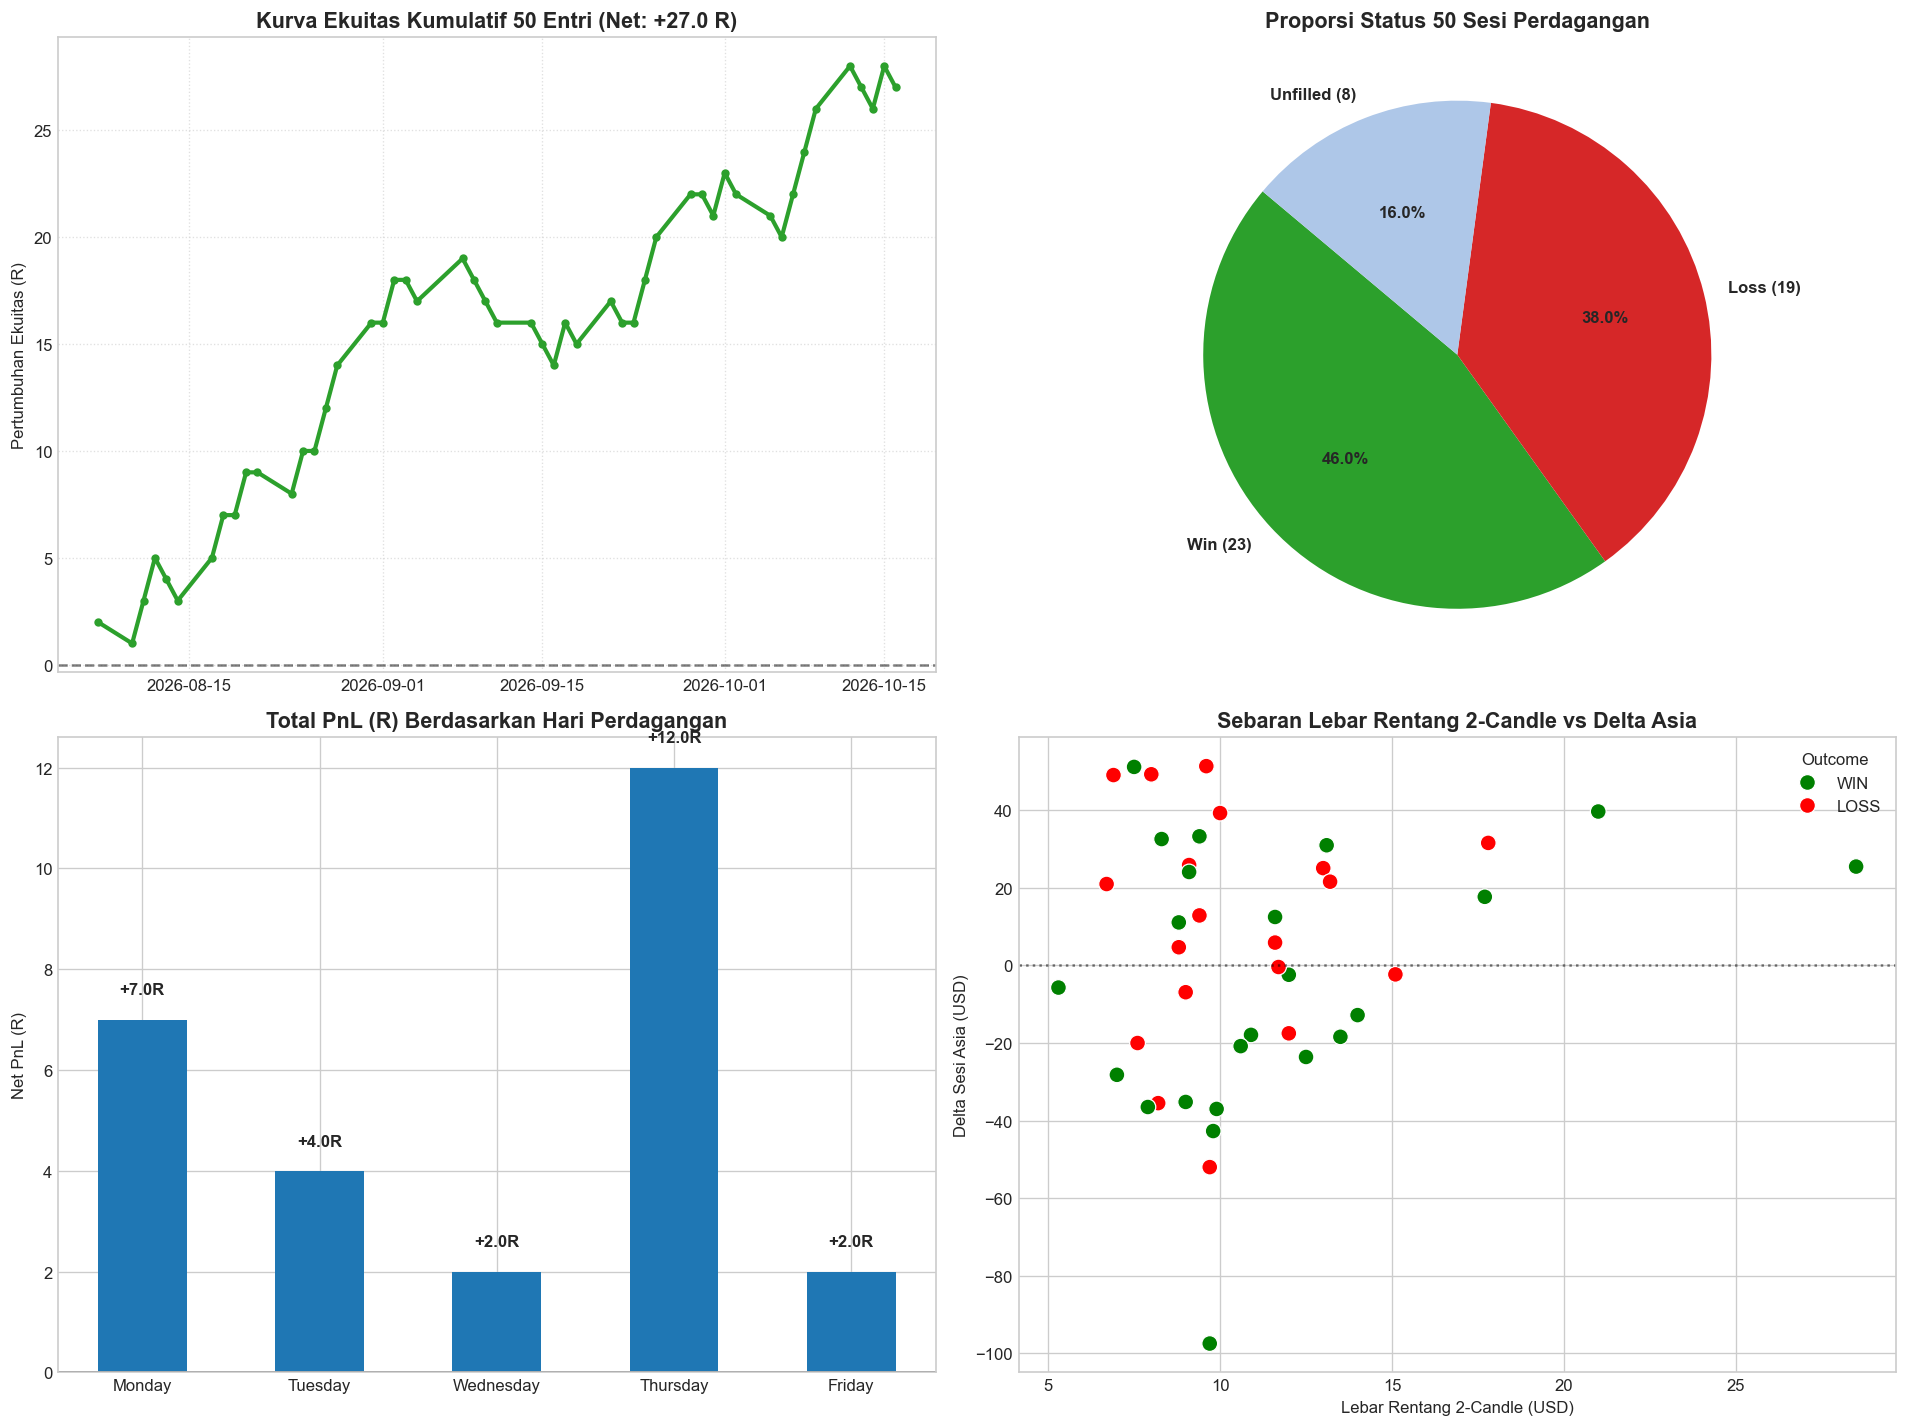

In [7]:
# 7. GRAFIK KOMPREHENSIF 50 ENTRI
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Kurva Ekuitas Kumulatif
df_50['Cum_PnL'] = df_50['PnL_R'].cumsum()
axes[0, 0].plot(df_50['Date'], df_50['Cum_PnL'], color='#2ca02c', linewidth=2.5, marker='o', markersize=4)
axes[0, 0].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[0, 0].set_title(f"Kurva Ekuitas Kumulatif 50 Entri (Net: {total_pnl:+.1f} R)", fontsize=13, fontweight='bold')
axes[0, 0].set_ylabel("Pertumbuhan Ekuitas (R)")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# 2. Proporsi Hasil Eksekusi
counts = [wins, losses, unfilled]
labels = [f"Win ({wins})", f"Loss ({losses})", f"Unfilled ({unfilled})"]
colors = ['#2ca02c', '#d62728', '#aec7e8']
axes[0, 1].pie(counts, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontweight': 'bold'})
axes[0, 1].set_title("Proporsi Status 50 Sesi Perdagangan", fontsize=13, fontweight='bold')

# 3. Distribusi PnL per Hari
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
day_stats = df_50.groupby("Day")["PnL_R"].agg(['count', 'sum', lambda x: (x > 0).mean() * 100]).reindex(day_order)
day_stats.columns = ['Count', 'PnL_R', 'WinRate']
axes[1, 0].bar(day_stats.index, day_stats['PnL_R'], color=['#1f77b4' if x > 0 else '#d62728' for x in day_stats['PnL_R']], width=0.5)
axes[1, 0].axhline(0, color='black', linewidth=1)
axes[1, 0].set_title("Total PnL (R) Berdasarkan Hari Perdagangan", fontsize=13, fontweight='bold')
axes[1, 0].set_ylabel("Net PnL (R)")
for i, (day, row) in enumerate(day_stats.iterrows()):
    p = row['PnL_R']
    axes[1, 0].text(i, p + (0.5 if p >= 0 else -1.2), f"{p:+.1f}R", ha='center', fontsize=10, fontweight='bold')

# 4. Sebaran Lebar Rentang vs Hasil
sns.scatterplot(data=df_50[df_50['Triggered']], x='Range', y='Asia_Delta', hue='Outcome', palette={'WIN': 'green', 'LOSS': 'red'}, s=90, ax=axes[1, 1])
axes[1, 1].axhline(0, color='black', linestyle=':', alpha=0.5)
axes[1, 1].set_title("Sebaran Lebar Rentang 2-Candle vs Delta Asia", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Lebar Rentang 2-Candle (USD)")
axes[1, 1].set_ylabel("Delta Sesi Asia (USD)")

plt.tight_layout()
plt.show()


---
## 8. Ringkasan & SOP Eksekusi
### Metrik Utama 50 Entri:
- **Total Sesi Diuji**: 50 hari perdagangan.
- **Order Terpicu**: 42 trade (Rasio eksekusi 84.0%).
- **Hasil**: 23 Menang, 19 Kalah.
- **Win Rate**: 54.8% (naik ke 60.0% pada pergerakan Asia $\ge \$10$).
- **Risk to Reward**: 1 : 2.
- **Net Profit**: **+27.00 R** (Akumulasi 27 kali unit risiko).
- **Profit Factor**: **2.42**.
- **Max Drawdown**: **-4.00 R**.

### SOP Eksekusi (14.25 – 14.30 WIB):
1. **14.25 WIB - Tentukan Arah Tren Asia**:
   - Hitung $\Delta Asia = Close_{13.45} - Open_{07.00}$.
   - $\Delta Asia \ge 0 ightarrow$ Siapkan **BUY LIMIT** di level Low 14.00-14.15.
   - $\Delta Asia < 0 ightarrow$ Siapkan **SELL LIMIT** di level High 14.00-14.15.
2. **14.30 WIB - Pasang Limit Order**:
   - Hitung $Range = High - Low$.
   - Tentukan $SL = 0.5 	imes Range$ dan $TP = 1.0 	imes Range$ (level batas sebaliknya).
   - Pasang order.
3. **22.00 WIB - Penutupan Akhir Sesi**:
   - Tutup posisi aktif jika belum mencapai TP/SL.
   - Batalkan order jika belum terpicu (*unfilled*).
